# CITS5508 - Assignment 2 2026

Dipika Choudhury - 23779727

## Part 1 - Ensemble Learning for Heart Disease Prediction

### 1. Load the dataset and assign appropriate column names.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

heart = pd.read_csv(
    "processed.cleveland.data",
    names=column_names,
    na_values="?"
)

heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
print("Original shape:", heart.shape)

print("\nMissing values:")
print(heart.isna().sum())

heart = heart.dropna()

print("\nShape after dropping the values that are missing:", heart.shape)

Original shape: (297, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Shape after dropping missing values: (297, 14)


### Briefly describe the dataset:
### (a) How many examples are there? What does each example represent?
There are 303 examples in the original dataset that has 14 columns, and as shown above, there's 297 remaining examples after dropping missing values. Each one of the examples represent one record of a patient from the Cleveland Heart Disease database. The columns illustrate information about patients like age, sex, chest pain type, resting blood pressure, serum cholesterol, fasting blood sugar, maximum heart rate achieved, among other pieces of information.

### (b) How many features are there? Which are numeric and which are categorical?
As mentioned, there are 14 columns. Out of these, 1 is the target and the other 13 are the features. As per the 'Variables Table', the numerical or integer type features are: age, trestbps, chol, thalaxh, oldpeak, and ca. On the other hand, the categorical features are sex, cp, fbs, restecg, exang, slope, and thal.

### (c) Describe the target attribute (num). The original target indicates the severity of heart disease on an integer scale from 0 to 4. For this assignment, binarise the target: 0 indicates absence of disease, and any value greater than 0 indicates presence.
The original target attribute is num, which records heart disease severity from 0 to 4. 0 would mean there is no heart disease, while a value of 1-4 shows increasing severity of heart disease. Since this assignment treats the problem as binary classification, I created a new target variable where 0 represents absence of heart disease and 1 represents presence of heart disease. This step is shown in the code cell below.

In [14]:
heart["target"] = (heart["num"] > 0).astype(int)

heart[["num", "target"]].head(10)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


### 2. Split the dataset into a training and testing set. Use 80% of the data for training, and 20% for testing. Make sure to stratify your split.

In [ ]:
from sklearn.model_selection import train_test_split

X = heart.drop(columns=["num", "target"])
y = heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", X_train.shape[0])
print("Test examples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training examples: 237
Testing examples: 60
Number of features: 13


### 3. Fit a single Decision Tree classifier using scikit-learn as a baseline and evaluate its performance on the test set.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred_dt)],
    "Precision": [precision_score(y_test, y_pred_dt)],
    "Recall": [recall_score(y_test, y_pred_dt)],
    "F1-score": [f1_score(y_test, y_pred_dt)]
})

dt_results

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7,0.692308,0.642857,0.666667


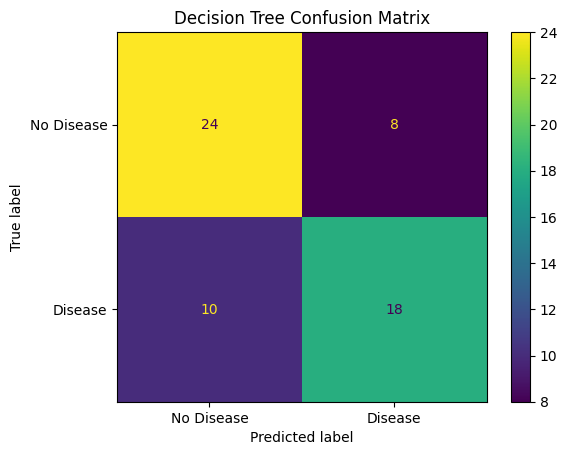

In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Disease", "Disease"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

### 4. Fit two further ensemble models using scikit-learn:

#### - A Random Forest classifier with 500 estimators.
#### - An AdaBoost classifier with 500 estimators.

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

ada_model = AdaBoostClassifier(
    n_estimators=500,
    random_state=42
)

rf_model.fit(X_train, y_train)
ada_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_ada = ada_model.predict(X_test)

ensemble_results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada)
    ],
    "Precision": [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada)
    ],
    "Recall": [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada)
    ]
})

ensemble_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.867,0.885,0.821,0.852
1,AdaBoost,0.850,0.828,0.857,0.842


### 5. Combine your models from the previous steps in a soft-voting Voting Classifier.

In [ ]:
voting_model = VotingClassifier(
    estimators=[
        ("decision_tree", dt_model),
        ("random_forest", rf_model),
        ("adaboost", ada_model)
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)

y_pred_voting = voting_model.predict(X_test)

voting_results = pd.DataFrame({
    "Model": ["Voting Classifier"],
    "Accuracy": [accuracy_score(y_test, y_pred_voting)],
    "Precision": [precision_score(y_test, y_pred_voting)],
    "Recall": [recall_score(y_test, y_pred_voting)],
    "F1-score": [f1_score(y_test, y_pred_voting)]
})

voting_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Voting Classifier,0.717,0.72,0.643,0.679


### 6. Compare the performance of all four models (the decision tree baseline, the Random Forest, the AdaBoost classifier, and the voting classifier) on the test set:

### (a) Create a table of precision, recall, and F1-scores for each model.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Voting Classifier"
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada),
        precision_score(y_test, y_pred_voting)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada),
        recall_score(y_test, y_pred_voting)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada),
        f1_score(y_test, y_pred_voting)
    ]
})

model_results.round(3)

,Model,Precision,Recall,F1-score
0,Decision Tree,0.692,0.643,0.667
1,Random Forest,0.885,0.821,0.852
2,AdaBoost,0.828,0.857,0.842
3,Voting Classifier,0.720,0.643,0.679


### (b) Display a confusion matrix for each model.

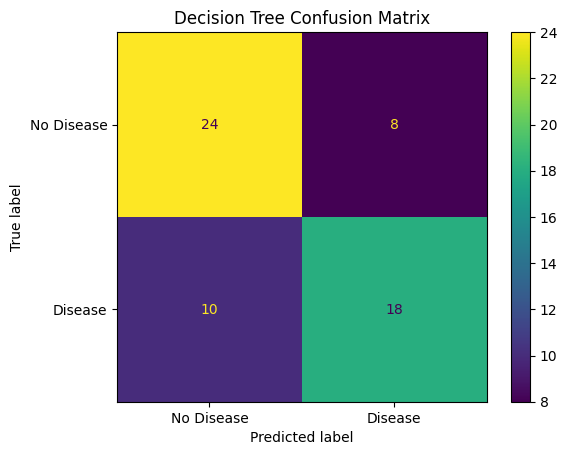

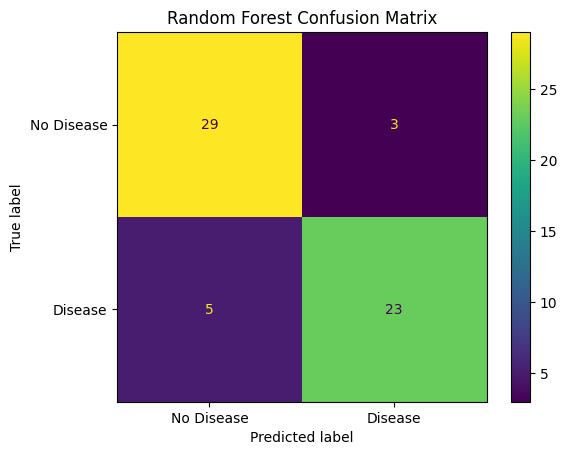

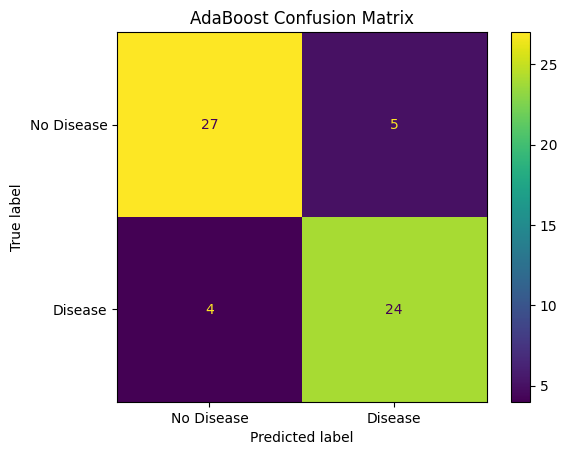

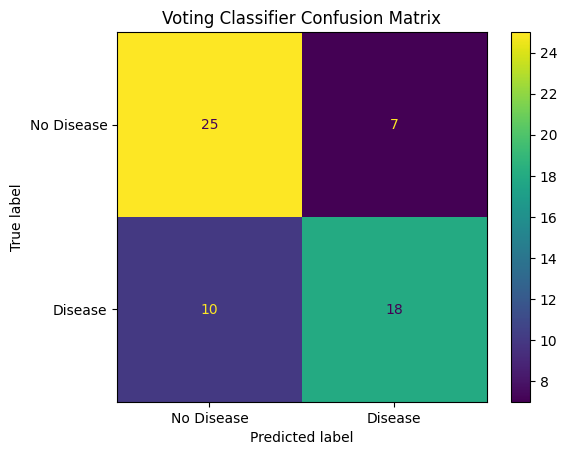

In [ ]:
models_and_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "Voting Classifier": y_pred_voting
}

for model_name, predictions in models_and_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Disease"]
    )

    disp.plot()
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

blah blah description

### 7. Plot the feature importances of your Random Forest. Briefly comment on which features contribute most strongly to predictions, and whether this matches what you would expect.

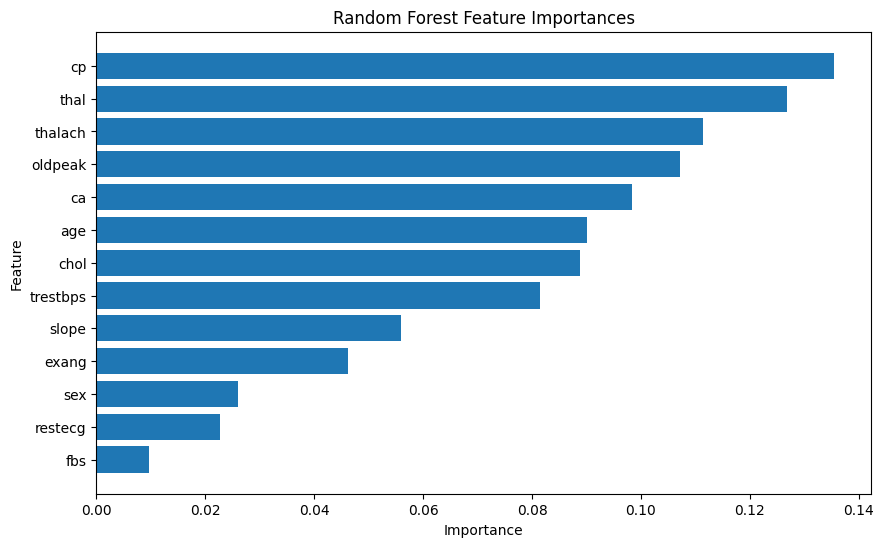

In [ ]:
feature_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importances = feature_importances.sort_values(
    by="Importance",
    ascending=False
)

feature_importances

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importances["Feature"],
    feature_importances["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importances")
plt.show()

Blah blah comment

### 8. Comment on your results in detail. Investigate the following ideas:

#### (a) How do the models compare to each other? Which model performs best? Is this what you expected?

### (b) Bagging and boosting reduce different sources of error. Which type of ensemble works better here, and why might that be?


### (c) What are the advantages and disadvantages of using an ensemble method over the decision tree baseline?

## Part 2 - Clustering of Faces

### 1. Load the Olivetti Faces dataset using the code above.

In [ ]:
from sklearn.datasets import fetch_olivetti_faces
data, targets = fetch_olivetti_faces(return_X_y=True)

### Briefly describe the dataset:

### (a) How many examples are there? What does each example represent?

### (b) Describe the features. How many features are there, and what does each feature represent?